# 02 - Verificación de Normalidad (Shapiro-Wilk)

## Objetivo
- Verificar normalidad de las distribuciones de las métricas
- Determinar si corresponde usar tests paramétricos o no paramétricos
- Visualizar distribuciones con histogramas y Q-Q plots

In [1]:
import json
import polars as pl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from pathlib import Path

plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 8)})

DATA_DIR = Path("..") / "part_i"

## 1. Carga de datos

In [2]:
df_combined = pl.read_csv(DATA_DIR / "combined_metrics_for_analysis.csv")
print(f"Datos: {df_combined.shape}")

# Cargar VR seleccionadas desde el archivo compartido
with open("vr_seleccionadas.json", "r", encoding="utf-8") as f:
    vr_config = json.load(f)

VR_SELECCIONADAS = vr_config["vr_seleccionadas"]
print(f"\nVR seleccionadas ({len(VR_SELECCIONADAS)}):")
for vr in VR_SELECCIONADAS:
    print(f"  - {vr}")

Datos: (711, 22)

VR seleccionadas (1):
  - respuesta_correcta_avg


## 2. Test de Shapiro-Wilk global (todas las observaciones)

H₀: la distribución es normal. Si p < 0.05, se rechaza normalidad.

In [3]:
shapiro_results = []

for metrica in VR_SELECCIONADAS:
    data = df_combined[metrica].drop_nulls().to_numpy()
    if len(data) >= 3:
        stat_val, p_val = stats.shapiro(data)
        shapiro_results.append({
            "metrica": metrica,
            "n": len(data),
            "shapiro_W": round(stat_val, 6),
            "p_value": p_val,
            "es_normal_005": p_val >= 0.05,
        })

df_shapiro = pl.DataFrame(shapiro_results).sort("p_value")
display(df_shapiro)

metrica,n,shapiro_W,p_value,es_normal_005
str,i64,f64,f64,i64
"""respuesta_correcta_avg""",684,0.88311,2.7242e-22,0


In [4]:
n_normal = df_shapiro.filter(pl.col("es_normal_005").cast(pl.Boolean)).height
n_total = df_shapiro.height
print(f"\nMétricas que pasan normalidad (α=0.05): {n_normal}/{n_total}")
print(f"Métricas que NO pasan normalidad: {n_total - n_normal}/{n_total}")
print("\n→ Conclusión: se deben usar tests no paramétricos." if n_normal < n_total / 2 else "\n→ Algunas métricas son normales, pero se recomienda cautela.")



Métricas que pasan normalidad (α=0.05): 0/1
Métricas que NO pasan normalidad: 1/1

→ Conclusión: se deben usar tests no paramétricos.


## 3. Shapiro-Wilk por grupo (estrategia × modelo)

Verificar normalidad dentro de cada grupo experimental.

In [5]:
shapiro_by_group = []

for estrategia in df_combined["estrategia"].unique().sort().to_list():
    for modelo in df_combined["id_modelo_especialista"].unique().sort().to_list():
        subset = df_combined.filter(
            (pl.col("estrategia") == estrategia) & (pl.col("id_modelo_especialista") == modelo)
        )
        for metrica in VR_SELECCIONADAS:
            data = subset[metrica].drop_nulls().to_numpy()
            if len(data) >= 3:
                stat_val, p_val = stats.shapiro(data)
                shapiro_by_group.append({
                    "estrategia": estrategia,
                    "modelo": modelo,
                    "metrica": metrica,
                    "n": len(data),
                    "shapiro_W": round(stat_val, 6),
                    "p_value": p_val,
                    "es_normal_005": p_val >= 0.05,
                })

df_shapiro_groups = pl.DataFrame(shapiro_by_group)

# Resumen: proporción de grupos normales por métrica
resumen = df_shapiro_groups.group_by("metrica").agg(
    pl.col("es_normal_005").sum().alias("grupos_normales"),
    pl.col("es_normal_005").count().alias("total_grupos"),
    (pl.col("es_normal_005").sum() / pl.col("es_normal_005").count()).alias("proporcion_normales"),
).sort("proporcion_normales")

display(resumen)

metrica,grupos_normales,total_grupos,proporcion_normales
str,i64,u32,f64
"""respuesta_correcta_avg""",0,9,0.0


## 4. Histogramas y Q-Q plots

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

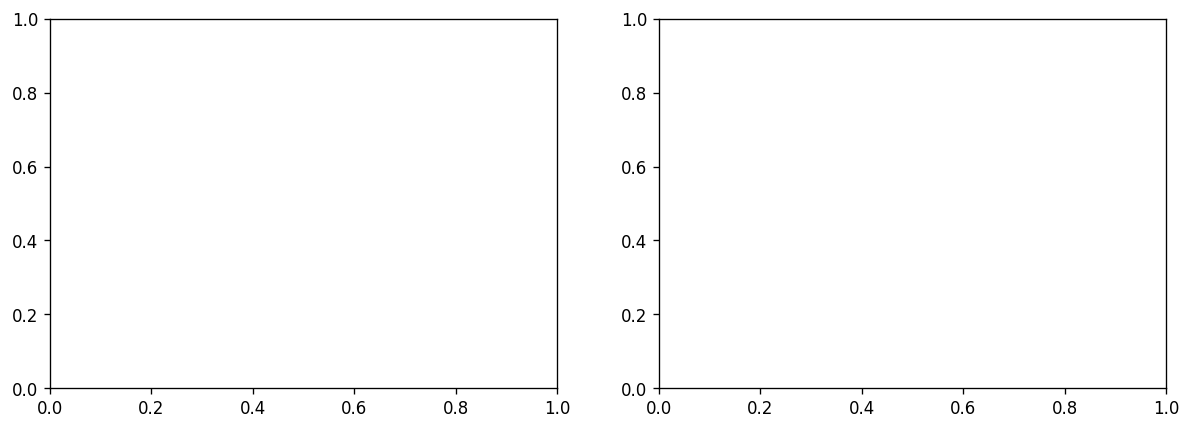

In [6]:
fig, axes = plt.subplots(len(VR_SELECCIONADAS), 2, figsize=(12, 4 * len(VR_SELECCIONADAS)))

for i, metrica in enumerate(VR_SELECCIONADAS):
    data = df_combined[metrica].drop_nulls().to_numpy()

    # Histograma
    ax_hist = axes[i, 0]
    ax_hist.hist(data, bins=30, density=True, alpha=0.7, edgecolor="black")
    mu, sigma = data.mean(), data.std()
    x = np.linspace(data.min(), data.max(), 100)
    if sigma > 0:
        ax_hist.plot(x, stats.norm.pdf(x, mu, sigma), "r-", linewidth=2, label="Normal teórica")
    ax_hist.set_title(f"{metrica} - Histograma", fontsize=10)
    ax_hist.legend(fontsize=8)

    # Q-Q plot
    ax_qq = axes[i, 1]
    stats.probplot(data, dist="norm", plot=ax_qq)
    ax_qq.set_title(f"{metrica} - Q-Q Plot", fontsize=10)

plt.tight_layout()
plt.show()

## 5. Resumen y conclusión

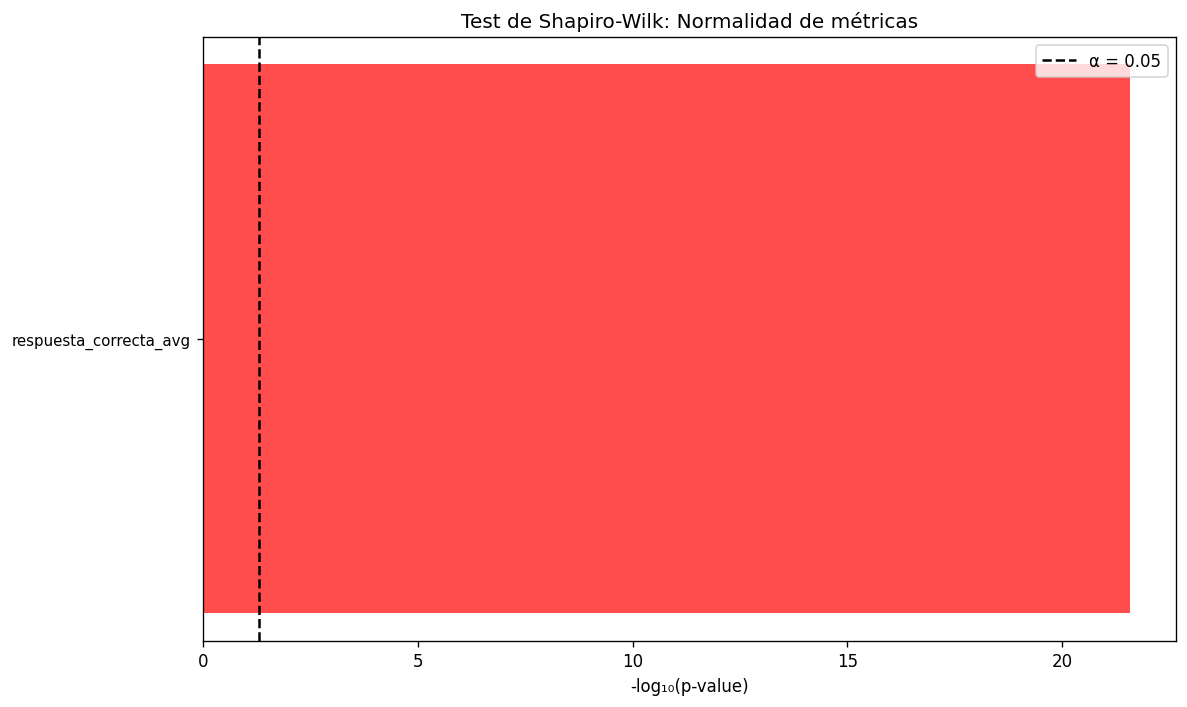


CONCLUSIÓN
Si la mayoría de las métricas no pasan el test de Shapiro-Wilk,
se confirma el uso de tests no paramétricos:
  - Kruskal-Wallis (en lugar de ANOVA)
  - Wilcoxon signed-rank (en lugar de t-test pareado)
  - Dunn con corrección de Bonferroni (post-hoc)

Las métricas del LLM-Judge son ordinales (0.0/0.25/0.5/0.75/1.0),
lo que refuerza adicionalmente el uso de tests no paramétricos.


In [7]:
# Tabla resumen visual
fig, ax = plt.subplots(figsize=(10, 6))

metricas_labels = df_shapiro["metrica"].to_list()
p_values = df_shapiro["p_value"].to_list()
colors = ["green" if p >= 0.05 else "red" for p in p_values]

bars = ax.barh(range(len(metricas_labels)), [-np.log10(p) for p in p_values], color=colors, alpha=0.7)
ax.axvline(x=-np.log10(0.05), color="black", linestyle="--", label="α = 0.05")
ax.set_yticks(range(len(metricas_labels)))
ax.set_yticklabels(metricas_labels, fontsize=9)
ax.set_xlabel("-log₁₀(p-value)")
ax.set_title("Test de Shapiro-Wilk: Normalidad de métricas")
ax.legend()
ax.invert_yaxis()

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("CONCLUSIÓN")
print("="*60)
print("Si la mayoría de las métricas no pasan el test de Shapiro-Wilk,")
print("se confirma el uso de tests no paramétricos:")
print("  - Kruskal-Wallis (en lugar de ANOVA)")
print("  - Wilcoxon signed-rank (en lugar de t-test pareado)")
print("  - Dunn con corrección de Bonferroni (post-hoc)")
print("\nLas métricas del LLM-Judge son ordinales (0.0/0.25/0.5/0.75/1.0),")
print("lo que refuerza adicionalmente el uso de tests no paramétricos.")